<a href="https://colab.research.google.com/github/jfbadarom/Fisica-com-Python/blob/main/ProjectLEntropy.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Trabalho Final Física com Python

In [2]:
!pip install qiskit qiskit-aer

In [3]:
import numpy as np
import scipy.linalg as la
import matplotlib.pyplot as plt
from qiskit.quantum_info import Statevector, DensityMatrix, partial_trace, entropy, random_statevector
from itertools import combinations


In [4]:

d = 5
n_partes = 5

#Nota 1: Embora eu esteja tentando fazer uma generalização para de dimensão e partes, ainda estou considerando que todas as partes tem a mesma dimensão o que no sistema mais geral possível não é uma verdade.
#Nota 2: Considerando apenas estados puros.
#Vou construir generalização de um estado Phi+ de N partes e d dimensões
total_dim = d ** n_partes
vec = np.zeros(total_dim, dtype=complex)
step = (d**n_partes - 1) // (d - 1)
for i in range(d):
    vec[i * step] = 1.0 / np.sqrt(d)

#Criando o vetor e a matriz densidade usando a biblioteca do Qiskit
phi_plus = Statevector(vec, dims=(d,) * n_partes)
rho = DensityMatrix(phi_plus)


In [5]:

# Tira o traço parcial dos subsistemas escolhidos
rho_reduzido= partial_trace(rho, [1, 2, 4])
#Entropia do estado reduzido
print("Entropia do subsistema individual (base 2):", entropy(rho_reduzido, base=2))


Entropia do subsistema individual (base 2): 2.3219280948873626


O qiskit não tem uma função nativa para a entropia condicional então vamos definir uma função para isso.

In [6]:
def conditional_entropy(rho, subsystem_indices):#subsytem_indices são os indices dos subsistemas A quando S(A|B)=S(AB)-S(B)
  rho_reduzido = partial_trace(rho, subsystem_indices)
  return entropy(rho, base=2)-entropy(rho_reduzido, base=2)


Agora vamos precisar definir o que é a entropia refletida 𝚂ᵣ(A|B).

In [7]:
def reflected_entropy(rho, index_A, index_B, base=2):
  dlist= rho.dims()
  n = len(dlist)
  d_A=dlist[index_A]
  d_B=dlist[index_B]

  complementar=[i for i in range(n) if i not in (index_A, index_B)]
  rho_reduzido = partial_trace(rho, complementar)

  evals, evecs = la.eigh(rho_reduzido.data)
  evals = np.clip(evals, 0.0, None)#Transforma autovalores negativos em 0
  rho_sqrt= evecs @ np.diag(np.sqrt(evals)) @ evecs.conj().T #Matriz do estado de purificação canônica

  psi_vec = rho_sqrt.flatten(order='C')# Transforma o produto externo dos elementos de matriz em um produto tensorial de vetores. |i><j| -----> |i,j>
  norm = la.norm(psi_vec)#Normalização do vetor
  if norm > 0:
        psi_vec = psi_vec / norm

  # Criar o Statevector especificando explicitamente os 4 subsistemas
  psi_purificado = Statevector(psi_vec, dims=[d_A, d_B, d_A, d_B])


  rho_AA_estrela = partial_trace(psi_purificado, [1, 3]) #Tirando o traço em BB* do estado purificado

  return entropy(rho_AA_estrela, base=base)




In [8]:
def bipartite_l_entropy(rho, index_A, index_B, base=2):

    n = len(rho.dims())


    comp_A = [i for i in range(n) if i != index_A] #Complementar do sistema A
    rho_A = partial_trace(rho, comp_A) #Matriz densidade reduzida traçando todos os sistemas exceto A
    S_A = entropy(rho_A, base=base)


    comp_B = [i for i in range(n) if i != index_B]#Complementar do sistema B
    rho_B = partial_trace(rho, comp_B) #Matriz densidade reduzida traçando todos os sistemas exceto B
    S_B = entropy(rho_B, base=base)


    S_R = reflected_entropy(rho, index_A, index_B, base=base) # Entropia refletida para A e B

    l_AB = min(2 * S_A, 2 * S_B) - S_R #Calcula a L-entropy bipartida
    return max(0.0, float(l_AB))  # Trunca possíveis resíduos numéricos negativos para garantir entropia não-negativa


In [9]:
def multipartite_l_entropy(rho, base=2):
    n = len(rho.dims())
    pares = list(combinations(range(n), 2)) # Lista com todas as combinações de pares entre subsistemas de Rho

    l_valores = []
    for i, j in pares:
        l_ij = bipartite_l_entropy(rho, i, j, base=base) #Calcula a L-entropia de cada par de susbsistemas
        l_valores.append(l_ij)

    # Média geométrica: (prod(l_ij)) ** (2 / (n*(n-1)))
    prod_total = np.prod(l_valores) # Produto de todos as L-entropias bipartidas
    expoente = 2.0 / (n * (n - 1))

    l_total = prod_total ** expoente
    return l_total, l_valores

In [10]:
# L-entropia total de todas as partes
l_n_partes, valores_pares = multipartite_l_entropy(rho, base=2)

print("L-entropia multipartida:", l_n_partes)
print("Valores de cada par l_ij:", valores_pares)

L-entropia multipartida: 2.3219280948873626
Valores de cada par l_ij: [2.3219280948873626, 2.3219280948873626, 2.3219280948873626, 2.3219280948873626, 2.3219280948873626, 2.3219280948873626, 2.3219280948873626, 2.3219280948873626, 2.3219280948873626, 2.3219280948873626]


Definindo um estado aleatório.

In [11]:
d = 5
n_partes = 6


dims = (d,) * n_partes #Lista com a dimensão de cada subespaço
psi_random = random_statevector(dims) #Vetor aleatório gerado com as dimensões escolhidos a partir da medida de Haar

rho_random = DensityMatrix(psi_random) #Operador densidade


Medindo a L entropia desse estado.

In [12]:
l_n_partes, valores_pares = multipartite_l_entropy(rho_random, base=2)

print("L-entropia multipartida:", l_n_partes)
print("Valores de cada par l_ij:", valores_pares)

L-entropia multipartida: 4.528872438480506
Valores de cada par l_ij: [4.530733630926476, 4.5287753951123655, 4.522184699274665, 4.530116539716548, 4.51880519139164, 4.5306099683103165, 4.533504541028275, 4.524819848510585, 4.53749332648398, 4.526249250565173, 4.530084541856976, 4.529833737221038, 4.522329124029744, 4.541617070583416, 4.525983700415248]


Reproduzindo o gráfico.

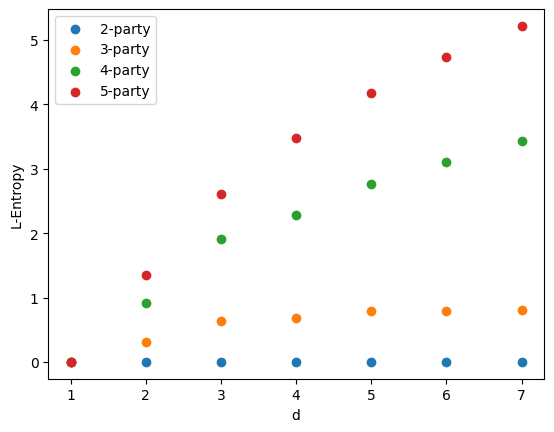

In [16]:
d_=[1,2,3,4,5,6,7]
n_partes=[2,3,4,5]

for n in n_partes:
  l=[]
  for d in d_:
    dims = (d,) * n
    psi_random = random_statevector(dims)
    rho_random = DensityMatrix(psi_random)
    l_n_partes, valores_pares = multipartite_l_entropy(rho_random, base=2)
    l.append(l_n_partes)
  plt.scatter(d_,l, label=f"{n}-party")
plt.xlabel('d')
plt.ylabel('L-Entropy')
plt.legend()


